# Fraud Detection | Interchecks

## Executive Summary

**Recommendation: Proceed with a controlled shadow pilot before replacing the existing fraud detection rule.**

### Key Findings

The retrospective results suggest that risk-based ranking could improve fraud detection at the same manual review workload.

In a seven-day test period, which contained 1,840 labeled fraudulent transactions:

- **Existing rule:** Identified 534 frauds under the daily review cap.
- **Model at the same workload:** Identified **1,656 frauds — approximately 3.1x the existing rule**, with no additional reviews.
- **Model at full review capacity:** Identified **1,839 frauds (99.95% recall)**, using up to 1,000 reviews per day.

The results suggest that a risk-based prioritization model could help investigators identify substantially more fraud using existing resources.

### Key Limitations

Despite the strong results, I would be cautious about assuming similar performance in production.

**1. Heavy reliance on balance information.** In a fixed-specification validation ablation, amount, type, and time alone captured 993 of 1,516 fraud cases (65.5%) under the review cap; adding origin balance features captured all 1,516. Permutation importance also ranked `amount_to_orig_balance` far above other inputs. These results raise concern that the model relies on synthetic balance patterns that may not generalize to real transactions. This ablation is a diagnostic, not the final selected model’s test result.

**2. Unusual transaction patterns.** Transaction volume drops sharply across the observation period while fraud prevalence increases. The final test day contains only 272 transactions, but all labeled fraudulent. These distribution shifts make the test results less representative of typical operating conditions.

**3. Retrospective evaluation.** The current approach ranks transactions after observing a full day's activity. Actual fraud review decisions must be made as transactions arrive, subject to staffing and review capacity.

### Recommended Next Steps

1. **Validate feature availability:** Confirm that account balances and other key inputs are available at the time of the transaction.
2. **Run a shadow pilot:** Score live transactions alongside the existing rule without changing current review decisions.
3. **Test operational feasibility:** Evaluate an arrival-time review queue under the 1,000-review daily limit.
4. **Assess real-world performance:** Compare fraud detected, missed fraud, false positives, and investigation effort before considering a phased rollout.

**Bottom line:** The model substantially outperforms the existing rule in this historical simulation, even at the same review workload. The strong balance dependence and dataset limitations warrant further validation before drawing conclusions about production performance.

---

**AI use:** I used AI tools to help draft the notebook and the code. I checked the analysis and am responsible for the conclusions.

> **Evaluation note:** The model and its limited hyperparameters were selected using the chronological validation window. The test results below are retrospective results on synthetic transactions; additional test diagnostics are exploratory because this test set has been inspected during notebook development. The summary figures above are updated to match the executed outputs in this notebook.

## 1. Setup

In [1]:
import kagglehub, glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, roc_auc_score

RANDOM_SEED = 42
REVIEW_CAP = 1000  
REVIEW_THRESHOLD = 200000

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data loading, integrity checks and baseline

I check the transaction mix, labels, amount/balance consistency and the stated rule before modeling. Balance reconciliation uses post-transaction fields **for data auditing only**; the model never receives `newbalanceOrig` or `newbalanceDest`.

In [2]:
# Download latest version
path = kagglehub.dataset_download("dylanmoraes/credit-card-fraud-dataset")
print("Path to dataset files:", path)
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("CSV files found:", csv_files)

dtypes = {"step": "int16", "type": "category", "amount": "float64",
          "nameOrig": "string", "nameDest": "string",
          "oldbalanceOrg": "float64", "newbalanceOrig": "float64",
          "oldbalanceDest": "float64", "newbalanceDest": "float64",
          "isFraud": "int8", "isFlaggedFraud": "int8"}
df = pd.read_csv(csv_files[0], dtype=dtypes)
print(df.shape)  # expect (6362620, 11)
# assert df.shape[1] == 11
# assert df["isFraud"].isin([0, 1]).all()
# print(df.dtypes.to_string())
display(df.head())

Path to dataset files: /Users/shiran/.cache/kagglehub/datasets/dylanmoraes/credit-card-fraud-dataset/versions/1
CSV files found: ['/Users/shiran/.cache/kagglehub/datasets/dylanmoraes/credit-card-fraud-dataset/versions/1/Fraud.csv']
(6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


Transactions: 6,362,620 | Fraud cases: 8,213 | Fraud rate: 0.129%
Missing cells: 0 | Duplicate rows: 0


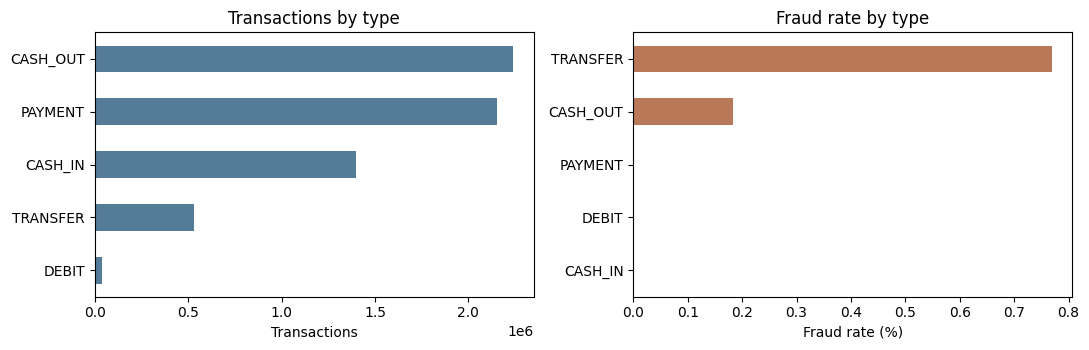

In [3]:
print(f"Transactions: {len(df):,} | Fraud cases: {df.isFraud.sum():,} | Fraud rate: {df.isFraud.mean():.3%}")
print(f"Missing cells: {df.isna().sum().sum():,} | Duplicate rows: {df.duplicated().sum():,}")

by_type = df.groupby("type", observed=True).isFraud.agg(["size", "sum"])
by_type["fraud_rate"] = by_type["sum"] / by_type["size"] * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
by_type["size"].sort_values().plot.barh(ax=axes[0], color="#547c98")
by_type["fraud_rate"].sort_values().plot.barh(ax=axes[1], color="#b97959")
axes[0].set(title="Transactions by type", xlabel="Transactions", ylabel="")
axes[1].set(title="Fraud rate by type", xlabel="Fraud rate (%)", ylabel="")
plt.tight_layout(); plt.show()

In [4]:
df["day"] = ((df.step.astype("int32") - 1) // 24).astype("int16")
df["rule_200k"] = ((df.type == "TRANSFER") & (df.amount > REVIEW_THRESHOLD)).astype("int8")
print("Rule comparison (rows = amount rule, columns = provided flag):")
display(pd.crosstab(df.rule_200k, df.isFlaggedFraud, margins=True))
for col in ["rule_200k", "isFlaggedFraud"]:
    flagged = df[col].astype(bool)
    print(f"{col}: flagged={flagged.sum():,}, fraud caught={df.loc[flagged,'isFraud'].sum():,}, "
          f"precision={df.loc[flagged,'isFraud'].mean() if flagged.any() else 0:.3%}, "
          f"max daily reviews={df.groupby('day', observed=True)[col].sum().max():,}")

Rule comparison (rows = amount rule, columns = provided flag):


isFlaggedFraud,0,1,All
rule_200k,,,
0,5953510,0,5953510
1,409094,16,409110
All,6362604,16,6362620


rule_200k: flagged=409,110, fraud caught=2,740, precision=0.670%, max daily reviews=36,073
isFlaggedFraud: flagged=16, fraud caught=16, precision=100.000%, max daily reviews=3


In [5]:
# Balance changes from each account's perspective
check = df[[
    "type", "amount", "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest", "isFraud"
]].copy()

check["orig_change"] = check["newbalanceOrig"] - check["oldbalanceOrg"]
check["dest_change"] = check["newbalanceDest"] - check["oldbalanceDest"]

# Expected direction of movement by transaction type
# Positive amount represents transaction magnitude, not cash-flow direction.
orig_sign = {
    "CASH_IN": 1,
    "CASH_OUT": -1,
    "DEBIT": -1,
    "PAYMENT": -1,
    "TRANSFER": -1,
}
dest_sign = {
    "CASH_IN": -1,
    "CASH_OUT": 1,
    "DEBIT": 1,
    "PAYMENT": 1,
    "TRANSFER": 1,
}

check["expected_orig"] = check["amount"] * check["type"].map(orig_sign)
check["expected_dest"] = check["amount"] * check["type"].map(dest_sign)

# Small tolerance for rounding differences
tol = 0.01

check["orig_match"] = np.isclose(
    check["orig_change"], check["expected_orig"], atol=tol, rtol=0
)
check["dest_match"] = np.isclose(
    check["dest_change"], check["expected_dest"], atol=tol, rtol=0
)

# Amount sign and missing-value checks
check["invalid_amount"] = check["amount"].isna() | (check["amount"] < 0)
check["missing_balance"] = check[
    ["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
].isna().any(axis=1)

summary = (
    check.groupby(["type", "isFraud"])
    .agg(
        transactions=("amount", "size"),
        invalid_amount_pct=("invalid_amount", "mean"),
        missing_balance_pct=("missing_balance", "mean"),
        orig_match_pct=("orig_match", "mean"),
        dest_match_pct=("dest_match", "mean"),
    )
    .reset_index()
)

pct_cols = [c for c in summary.columns if c.endswith("_pct")]
summary[pct_cols] = (summary[pct_cols] * 100).round(2)

display(summary)


,type,isFraud,transactions,invalid_amount_pct,missing_balance_pct,orig_match_pct,dest_match_pct
0,CASH_IN,0,1399284,0.0,0.0,92.09,63.86
1,CASH_OUT,0,2233384,0.0,0.0,10.88,80.16
2,CASH_OUT,1,4116,0.0,0.0,99.42,87.29
3,DEBIT,0,41432,0.0,0.0,70.21,80.07
4,PAYMENT,0,2151495,0.0,0.0,46.28,0.00
5,TRANSFER,0,528812,0.0,0.0,3.80,78.17
6,TRANSFER,1,4097,0.0,0.0,99.49,0.05


In [6]:
# Investigate destination balance behavior
dest_check = check.copy()

dest_check["dest_unchanged"] = np.isclose(
    dest_check["oldbalanceDest"],
    dest_check["newbalanceDest"],
    atol=0.01,
    rtol=0
)

dest_check["dest_both_zero"] = (
    (dest_check["oldbalanceDest"] == 0) &
    (dest_check["newbalanceDest"] == 0)
)

summary = (
    dest_check.groupby(["type", "isFraud"])
    .agg(
        transactions=("amount", "size"),
        dest_unchanged_pct=("dest_unchanged", "mean"),
        dest_both_zero_pct=("dest_both_zero", "mean"),
        dest_match_pct=("dest_match", "mean")
    )
    .mul(
        {"transactions": 1,
         "dest_unchanged_pct": 100,
         "dest_both_zero_pct": 100,
         "dest_match_pct": 100}
    )
    .round(2)
)

display(summary)

transactions  dest_unchanged_pct  dest_both_zero_pct  \
type     isFraud                                                         
CASH_IN  0             1399284               11.43               11.43   
CASH_OUT 0             2233384                0.07                0.07   
         1                4116                0.44                0.19   
DEBIT    0               41432                0.00                0.00   
PAYMENT  0             2151495              100.00              100.00   
TRANSFER 0              528812                0.02                0.02   
         1                4097               99.29               99.29   

                  dest_match_pct  
type     isFraud                  
CASH_IN  0                 63.86  
CASH_OUT 0                 80.16  
         1                 87.29  
DEBIT    0                 80.07  
PAYMENT  0                  0.00  
TRANSFER 0                 78.17  
         1                  0.05

### Data Quality & Initial Observations

The dataset contains **6.36 million transactions and 8,213 fraud cases (0.129%)**, with no missing values or duplicate rows.

A few findings stand out:

**1. Fraud is highly concentrated by transaction type.**

- Fraud appears only in `TRANSFER` and `CASH_OUT`, with fraud rates of approximately 0.77% and 0.18%, respectively.
- `CASH_OUT` has the highest transaction volume, while `TRANSFER` has the highest fraud rate.
- This suggests transaction type is an important predictor, although the absence of fraud in other categories may be specific to this dataset.

**2. The provided fraud flag does not represent the stated baseline rule.**

- The stated rule (`TRANSFER` above $200K) flags 409,110 transactions, identifying 2,740 fraud cases before applying the review cap.
- The provided `isFlaggedFraud` column flags only 16 transactions, all fraudulent.
- The amount rule generates up to 36,073 alerts in a single day, far exceeding the 1,000-review capacity.

I therefore reconstruct the stated amount rule as the primary baseline rather than relying on `isFlaggedFraud`. All subsequent comparisons apply the daily review cap.

**3. Balance reconciliation differs substantially between fraud and non-fraud transactions.**

- Approximately 99.5% of fraudulent `TRANSFER` and `CASH_OUT` transactions have origin balance changes consistent with the transaction amount, compared with only 3.8% and 10.9% of legitimate transactions, respectively.
- For fraudulent `TRANSFER` transactions, 99.3% have both destination balances recorded as zero, compared with just 0.02% of legitimate transfers.
- All `PAYMENT` transactions have zero destination balances, suggesting that balance fields may not be equally meaningful across transaction types.

**4. Potential implications for model reliability.**

The balance patterns are unusually distinct between fraudulent and legitimate transactions. They may reflect the synthetic data-generation process rather than generalizable fraud behavior.

This raises two questions for further validation: whether the balance features are genuinely available at decision time, and how much of the model's predictive performance depends on these patterns.

**Takeaway:** The dataset is complete at a basic structural level, but the transaction balance behavior and provided fraud flag require closer examination. I would proceed with modeling while treating balance-related results cautiously and testing their contribution through feature ablation.

## 3. Features and chronological evaluation

**Design:** I use pre-transaction attributes and prior account activity. Historical account aggregates are shifted to the start of the hour so that the current hour cannot influence its own features. Train, validation and test are separated by day; neither training nor preprocessing uses future labels.

**Primary selection metric:** number of labeled fraud cases in the highest-scored **up to 1,000 transactions per day** on validation. I also report recall and precision at capacity, average precision (PR-AUC), and ROC-AUC as a diagnostic. Accuracy is not useful as the main metric with this level of class imbalance.

**Rule comparator:** `TRANSFER` with `amount > $200,000`, capped at 1,000/day. When more than 1,000 rule alerts occur, the largest amounts are prioritized; this is an explicit assumption rather than a stated operational policy.

In [7]:
# Preserve original order for reproducibility; build historical features on hourly aggregates.
df["_row_id"] = np.arange(len(df), dtype=np.int32)
df.sort_values(["step", "_row_id"], inplace=True, kind="mergesort")
df.reset_index(drop=True, inplace=True)

# Pre-transaction attributes only.
features = pd.DataFrame(index=df.index)
features["amount_log"] = np.log1p(df.amount.clip(lower=0)).astype("float64")
features["oldbalance_org_log"] = np.log1p(df.oldbalanceOrg.clip(lower=0)).astype("float64")
features["oldbalance_dest_log"] = np.log1p(df.oldbalanceDest.clip(lower=0)).astype("float64")
features["amount_to_orig_balance"] = (df.amount / (df.oldbalanceOrg + 1)).clip(0, 1e6).astype("float64")
features["amount_to_dest_balance"] = (df.amount / (df.oldbalanceDest + 1)).clip(0, 1e6).astype("float64")
features["orig_balance_zero"] = (df.oldbalanceOrg == 0).astype("int8")
features["dest_balance_zero"] = (df.oldbalanceDest == 0).astype("int8")
features["hour_of_day"] = ((df.step.astype("int32") - 1) % 24).astype("int8")
features["day_index"] = df.day.astype("int16")
features["is_dest_merchant"] = df.nameDest.str.startswith("M").fillna(False).astype("int8")
features = pd.concat([features, pd.get_dummies(df.type, prefix="type", dtype="int8")], axis=1)

# Hourly aggregates, shifted by one hour for each account: no same-hour lookahead.
def prior_hour_features(account_col, prefix):
    hourly = (df.groupby([account_col, "step"], observed=True, sort=False)
                .agg(hour_count=("amount", "size"), hour_amount=("amount", "sum"))
                .reset_index())
    hourly.sort_values([account_col, "step"], inplace=True, kind="mergesort")
    g = hourly.groupby(account_col, observed=True, sort=False)
    hourly[f"{prefix}_prior_count"] = (g.hour_count.cumsum() - hourly.hour_count).astype("float64")
    hourly[f"{prefix}_prior_amount"] = (g.hour_amount.cumsum() - hourly.hour_amount).astype("float64")
    # Match each transaction to the history at the START of its hour.
    lookup = hourly.set_index([account_col, "step"])[[f"{prefix}_prior_count", f"{prefix}_prior_amount"]]
    idx = pd.MultiIndex.from_arrays([df[account_col].array, df.step.array], names=[account_col, "step"])
    values = lookup.reindex(idx)
    values.index = df.index
    return values

for acct_col, prefix in [("nameOrig", "orig"), ("nameDest", "dest")]:
    hist = prior_hour_features(acct_col, prefix)
    features = pd.concat([features, hist], axis=1)
    del hist

for col in ["orig_prior_count", "dest_prior_count", "orig_prior_amount", "dest_prior_amount"]:
    features[col] = np.log1p(features[col].clip(lower=0)).astype("float64")
features = features.replace([np.inf, -np.inf], np.nan).fillna(0)
assert not features.isna().any().any()
FEATURES = features.columns.tolist()
print(f"Engineered {len(FEATURES)} features")
print("Feature groups: amount, type, balances, time, prior account activity")

Engineered 19 features
Feature groups: amount, type, balances, time, prior account activity


Train: 6,008,416 rows; 4,857 frauds (0.0808%); days 0–17
Validation: 192,778 rows; 1,516 frauds (0.7864%); days 18–23
Test: 161,426 rows; 1,840 frauds (1.1398%); days 24–30


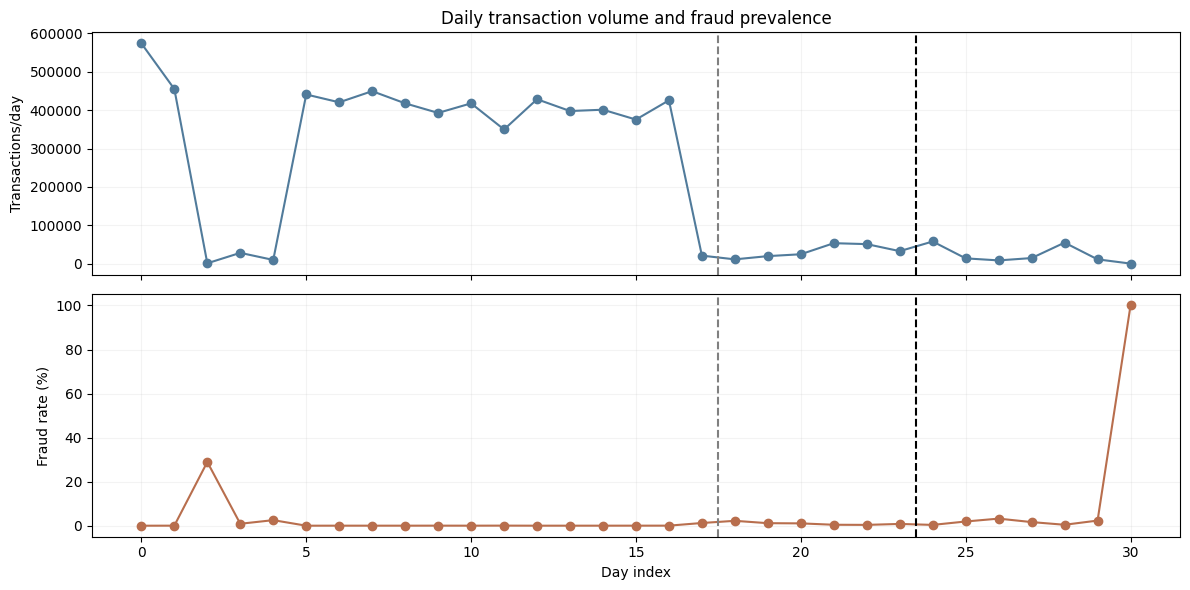

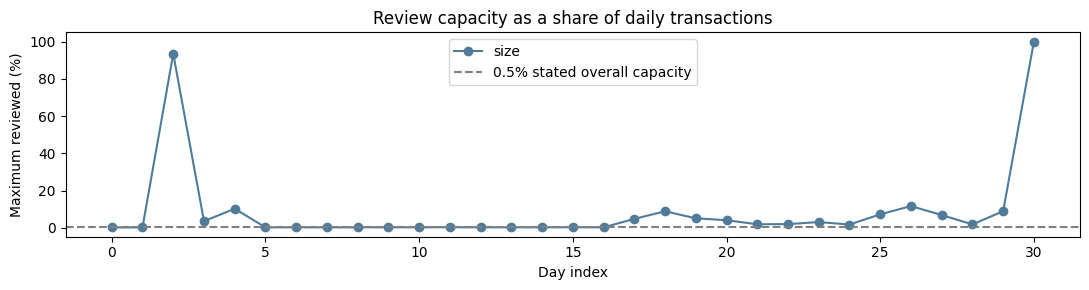

The final test day is small; see the full-day sensitivity check below.


In [8]:
days = np.sort(df.day.unique())
train_end = days[int(len(days)*0.60)]
valid_end = days[int(len(days)*0.80)]
train_mask = (df.day < train_end).to_numpy()
valid_mask = ((df.day >= train_end) & (df.day < valid_end)).to_numpy()
test_mask = (df.day >= valid_end).to_numpy()
y = df.isFraud.to_numpy(dtype=np.int8)
for name, mask in [("Train",train_mask),("Validation",valid_mask),("Test",test_mask)]:
    print(f"{name}: {mask.sum():,} rows; {y[mask].sum():,} frauds ({y[mask].mean():.4%}); "
          f"days {df.loc[mask,'day'].min()}–{df.loc[mask,'day'].max()}")

# Volume and prevalence must be read together: the same review cap means
# very different selection fractions when transaction volume changes.
fraud_by_day = (
    df.groupby("day", observed=True)["isFraud"]
    .agg(["size", "sum"])
)

fraud_by_day["rate_pct"] = (
    fraud_by_day["sum"] / fraud_by_day["size"] * 100
)
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
fraud_by_day["size"].plot(ax=axes[0], marker="o", color="#517b9b")
axes[0].set(ylabel="Transactions/day", title="Daily transaction volume and fraud prevalence")
fraud_by_day["rate_pct"].plot(ax=axes[1], marker="o", color="#b86e4d")
axes[1].set(ylabel="Fraud rate (%)", xlabel="Day index")
for ax in axes:
    ax.axvline(train_end-.5, ls="--", color="gray")
    ax.axvline(valid_end-.5, ls="--", color="black")
    ax.grid(alpha=.15)
plt.tight_layout(); plt.show()

# Show the fraction of transactions that can be reviewed at 1,000/day.
review_share = (REVIEW_CAP / fraud_by_day["size"]).clip(upper=1)*100
fig, ax = plt.subplots(figsize=(11, 3))
review_share.plot(ax=ax, marker="o", color="#517b9b")
ax.axhline(.5, ls="--", color="gray", label="0.5% stated overall capacity")
ax.set(title="Review capacity as a share of daily transactions", xlabel="Day index", ylabel="Maximum reviewed (%)")
ax.legend(); plt.tight_layout(); plt.show()
print("The final test day is small; see the full-day sensitivity check below.")

## 4. Model selection: simple baseline to gradient boosting

I compare the stated rule, two logistic regression specifications and two gradient boosting specifications, then run a **small, predefined** boosting parameter comparison. All model training uses the **full chronological training period**; only validation is used to choose the model. I select by fraud caught at the review cap, breaking ties using average precision and then the simpler specification. This is limited tuning, not an exhaustive search.

**Validation tie-break:** Four boosting configurations each captured 1,516 of 1,516 validation frauds at the daily cap. Among those ties, compact boosting with 180 iterations had the highest validation average precision (0.9915 versus 0.9913 for the next candidate). This is a small difference and should not be interpreted as a meaningful superiority claim. The code uses the candidate order only as a final tie-break if both capture and average precision are exactly equal.

In [9]:
# Full training period; no random row cap.
train_idx = np.flatnonzero(train_mask)
X_train = features.loc[train_mask]
y_train = y[train_mask]
X_valid = features.loc[valid_mask]
y_valid = y[valid_mask]
valid_days = df.loc[valid_mask, "day"].to_numpy()

models = {
    "Logistic (standard)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=300, solver="lbfgs")
    ),
    "Logistic (balanced)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=300, class_weight="balanced", solver="lbfgs")
    ),
    "Boosting (shallow)": HistGradientBoostingClassifier(
        max_iter=120, max_leaf_nodes=15, learning_rate=.08,
        l2_regularization=2., random_state=RANDOM_SEED
    ),
    "Boosting (deeper)": HistGradientBoostingClassifier(
        max_iter=180, max_leaf_nodes=31, learning_rate=.06,
        l2_regularization=5., random_state=RANDOM_SEED
    ),
}
print(f"Training on all {len(X_train):,} rows; {y_train.sum():,} fraud cases")

Training on all 6,008,416 rows; 4,857 fraud cases


In [10]:
def capacity_metrics(y_true, scores, days_arr, cap=1000):
    tmp = pd.DataFrame({"y": np.asarray(y_true, dtype=np.int8),
                        "score": np.asarray(scores, dtype=np.float64),
                        "day": np.asarray(days_arr)})
    # Stable tie break by original order. Review at most cap items on each day.
    tmp["order"] = np.arange(len(tmp))
    tmp.sort_values(["day", "score", "order"], ascending=[True,False,True], inplace=True, kind="mergesort")
    selected = tmp.groupby("day", sort=False).cumcount().lt(cap).to_numpy()
    reviewed = int(selected.sum()); caught = int(tmp.loc[selected,"y"].sum())
    fraud_total = int(tmp.y.sum()); n_days = int(tmp.day.nunique())
    return {"reviews_per_day": reviewed/n_days, "fraud_caught_per_day": caught/n_days,
            "fraud_missed_per_day": (fraud_total-caught)/n_days,
            "precision_at_cap": caught/reviewed if reviewed else np.nan,
            "recall_at_cap": caught/fraud_total if fraud_total else np.nan,
            "fraud_caught_total": caught}

def rule_metrics(mask, rule_col, cap=1000):
    sub = df.loc[mask, ["day","amount","isFraud",rule_col]].copy()
    sub = sub.loc[sub[rule_col].eq(1)]
    sub.sort_values(["day","amount"], ascending=[True,False], inplace=True, kind="mergesort")
    chosen = sub.groupby("day", sort=False).cumcount().lt(cap)
    total_fraud = int(df.loc[mask,"isFraud"].sum())
    days_count = df.loc[mask,"day"].nunique()
    reviewed = int(chosen.sum()); caught = int(sub.loc[chosen,"isFraud"].sum())
    return {"reviews_per_day":reviewed/days_count, "fraud_caught_per_day":caught/days_count,
            "fraud_missed_per_day":(total_fraud-caught)/days_count,
            "precision_at_cap":caught/reviewed if reviewed else np.nan,
            "recall_at_cap":caught/total_fraud if total_fraud else np.nan,
            "fraud_caught_total":caught}



Training: Logistic (standard)
Training: Logistic (balanced)
Training: Boosting (shallow)
Training: Boosting (deeper)
Training: Boosting (compact, 100)
Training: Boosting (compact, 180)
Training: Boosting (wide, 120)


,fraud_caught_total,recall_at_cap,precision_at_cap,reviews_per_day,pr_auc,roc_auc
method,,,,,,
Boosting (shallow),1516,1.0000,0.2527,1000.0000,0.9884,0.9999
"Boosting (compact, 180)",1516,1.0000,0.2527,1000.0000,0.9915,0.9999
"Boosting (wide, 120)",1516,1.0000,0.2527,1000.0000,0.9913,0.9999
Boosting (deeper),1516,1.0000,0.2527,1000.0000,0.9904,0.9999
"Boosting (compact, 100)",1515,0.9993,0.2525,1000.0000,0.9871,0.9999
Logistic (standard),1210,0.7982,0.2017,1000.0000,0.6410,0.9767
Logistic (balanced),1146,0.7559,0.1910,1000.0000,0.2349,0.9808
rule_200k,340,0.2243,0.0598,947.3333,NaN,NaN
isFlaggedFraud,1,0.0007,1.0000,0.1667,NaN,NaN


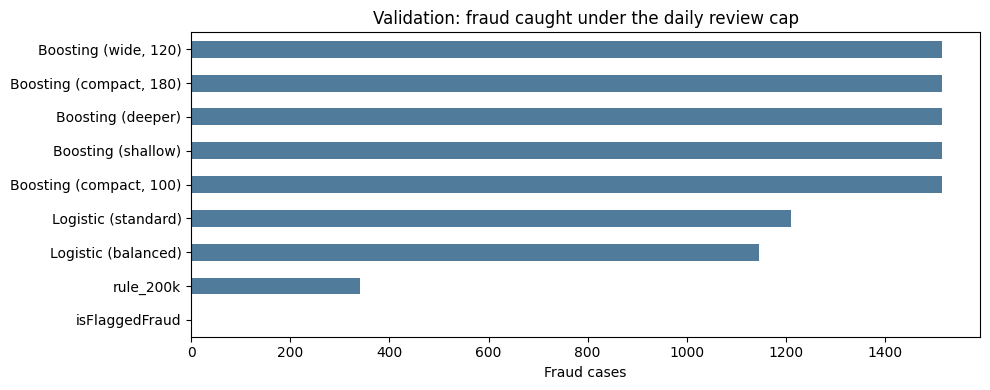

In [11]:
# Compare simple and more flexible models on the same validation window.
validation_scores = {}
for name, model in models.items():
    print("Training:", name, flush=True)
    model.fit(X_train, y_train)
    validation_scores[name] = model.predict_proba(X_valid)[:, 1].astype("float32")

# A few extra configurations; these also participate in validation selection.
extra_configs = {
    "Boosting (compact, 100)": (15, 100, .08, 3.),
    "Boosting (compact, 180)": (15, 180, .06, 3.),
    "Boosting (wide, 120)": (31, 120, .06, 3.),
}
for name, (leaves, iterations, rate, reg) in extra_configs.items():
    model = HistGradientBoostingClassifier(
        max_leaf_nodes=leaves, max_iter=iterations,
        learning_rate=rate, l2_regularization=reg,
        random_state=RANDOM_SEED
    )
    print("Training:", name, flush=True)
    model.fit(X_train, y_train)
    models[name] = model
    validation_scores[name] = model.predict_proba(X_valid)[:, 1].astype("float32")

rows = []
for col in ["isFlaggedFraud", "rule_200k"]:
    rows.append({"method": col, "pr_auc": np.nan, "roc_auc": np.nan,
                 **rule_metrics(valid_mask, col)})
for name, scores in validation_scores.items():
    rows.append({
        "method": name,
        "pr_auc": average_precision_score(y_valid, scores),
        "roc_auc": roc_auc_score(y_valid, scores),
        **capacity_metrics(y_valid, scores, valid_days, REVIEW_CAP)
    })
validation_results = pd.DataFrame(rows).set_index("method")
columns = ["fraud_caught_total", "recall_at_cap", "precision_at_cap",
           "reviews_per_day", "pr_auc", "roc_auc"]
display(validation_results[columns].sort_values("fraud_caught_total", ascending=False).round(4))
fig, ax = plt.subplots(figsize=(10, 4))
validation_results.fraud_caught_total.sort_values().plot.barh(ax=ax, color="#517b9b")
ax.set(title="Validation: fraud caught under the daily review cap", xlabel="Fraud cases", ylabel="")
plt.tight_layout(); plt.show()

In [12]:
# Choose on validation only. Prefer a simpler configuration for exact ties.
model_names = list(models)
model_complexity = {name: i for i, name in enumerate(model_names)}
ranked_models = validation_results.loc[model_names].copy()
ranked_models["complexity"] = [model_complexity[name] for name in model_names]
ranked_models = ranked_models.sort_values(
    ["fraud_caught_total", "pr_auc", "complexity"],
    ascending=[False, False, True]
)
best_name = ranked_models.index[0]
best_model = models[best_name]
print("Selected on validation:", best_name)
print(ranked_models[["fraud_caught_total", "recall_at_cap", "precision_at_cap", "pr_auc"]].head(5).round(4))

Selected on validation: Boosting (compact, 180)
                         fraud_caught_total  recall_at_cap  precision_at_cap  \
method                                                                         
Boosting (compact, 180)                1516         1.0000            0.2527   
Boosting (wide, 120)                   1516         1.0000            0.2527   
Boosting (deeper)                      1516         1.0000            0.2527   
Boosting (shallow)                     1516         1.0000            0.2527   
Boosting (compact, 100)                1515         0.9993            0.2525   

                         pr_auc  
method                           
Boosting (compact, 180)  0.9915  
Boosting (wide, 120)     0.9913  
Boosting (deeper)        0.9904  
Boosting (shallow)       0.9884  
Boosting (compact, 100)  0.9871  


## 5. Out-of-time model test: performance against the existing rule

This section evaluates the **validation-selected** model on the final chronological window. I report both the 1,000/day ceiling and **matched workload** (the same number of reviews as the rule on each day). The final low-volume day is separated as a sensitivity check. Results here are retrospective and should not be interpreted as production detection rates.

In [13]:
X_test = features.loc[test_mask]
y_test = y[test_mask]
test_days = df.loc[test_mask,"day"].to_numpy()
test_scores = best_model.predict_proba(X_test)[:,1].astype("float32")
test_rows = []
for col in ["isFlaggedFraud","rule_200k"]:
    test_rows.append({"method":col,"pr_auc":np.nan,"roc_auc":np.nan, **rule_metrics(test_mask,col)})
test_rows.append({"method":best_name,"pr_auc":average_precision_score(y_test,test_scores),
                  "roc_auc":roc_auc_score(y_test,test_scores),
                  **capacity_metrics(y_test,test_scores,test_days,REVIEW_CAP)})
test_results = pd.DataFrame(test_rows).set_index("method")
display(test_results.round(4))

baseline = test_results.loc["rule_200k"]
model_result = test_results.loc[best_name]
print(f"Incremental fraud caught/day vs stated amount rule: "
      f"{model_result.fraud_caught_per_day - baseline.fraud_caught_per_day:+.2f}")
print(f"Reviews/day: model {model_result.reviews_per_day:.0f}; "
      f"amount rule {baseline.reviews_per_day:.0f}")

,pr_auc,roc_auc,reviews_per_day,fraud_caught_per_day,fraud_missed_per_day,precision_at_cap,recall_at_cap,fraud_caught_total
method,,,,,,,,
isFlaggedFraud,NaN,NaN,1.2857,1.2857,261.5714,1.0000,0.0049,9
rule_200k,NaN,NaN,747.2857,76.2857,186.5714,0.1021,0.2902,534
"Boosting (compact, 180)",0.9926,0.9998,896.0000,262.7143,0.1429,0.2932,0.9995,1839


Incremental fraud caught/day vs stated amount rule: +186.43
Reviews/day: model 896; amount rule 747


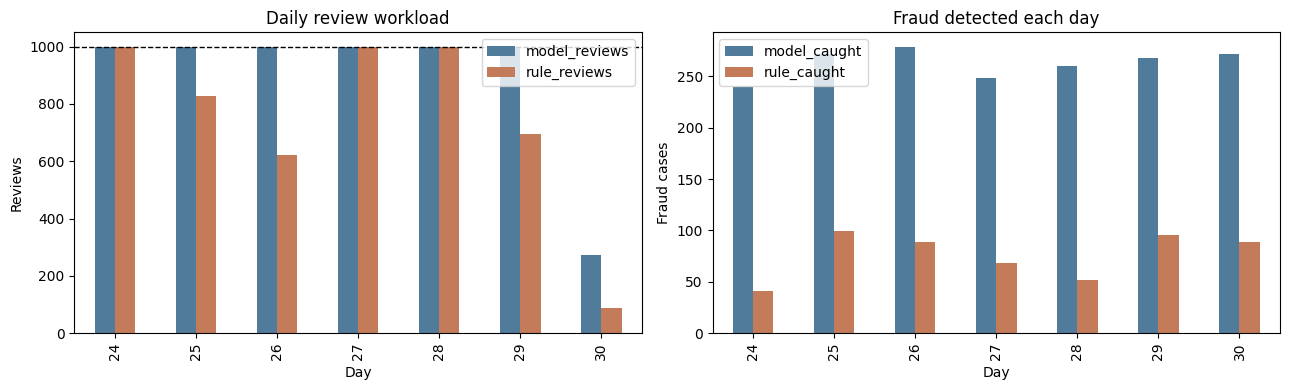

Day-by-day review cap utilization: {24: 1.0, 25: 1.0, 26: 1.0, 27: 1.0, 28: 1.0, 29: 1.0, 30: 0.272}
Final day transaction count: 272


In [14]:
# Daily operational outcomes: model versus capped rule.
def daily_selection(y_true, scores, days_arr, cap=1000):
    tmp = pd.DataFrame({"y": np.asarray(y_true, dtype=np.int8),
                        "score": np.asarray(scores), "day": np.asarray(days_arr)})
    tmp["row"] = np.arange(len(tmp))
    tmp = tmp.sort_values(["day", "score", "row"], ascending=[True, False, True], kind="mergesort")
    return tmp.loc[tmp.groupby("day", sort=False).cumcount().lt(cap)].copy()

def daily_rule_selection(mask, rule_col, cap=1000):
    sub = df.loc[mask, ["day", "amount", "isFraud", rule_col]].copy()
    sub = sub[sub[rule_col].eq(1)]
    sub = sub.sort_values(["day", "amount"], ascending=[True, False], kind="mergesort")
    return sub.loc[sub.groupby("day", sort=False).cumcount().lt(cap)].copy()

model_sel = daily_selection(y_test, test_scores, test_days, REVIEW_CAP)
rule_sel = daily_rule_selection(test_mask, "rule_200k", REVIEW_CAP)
daily = pd.DataFrame(index=np.sort(np.unique(test_days)))
daily["transactions"] = pd.Series(test_days).value_counts().reindex(daily.index, fill_value=0)
daily["frauds"] = pd.Series(y_test).groupby(test_days).sum().reindex(daily.index, fill_value=0)
daily["model_reviews"] = model_sel.groupby("day").size().reindex(daily.index, fill_value=0)
daily["rule_reviews"] = rule_sel.groupby("day").size().reindex(daily.index, fill_value=0)
daily["model_caught"] = model_sel.groupby("day").y.sum().reindex(daily.index, fill_value=0)
daily["rule_caught"] = rule_sel.groupby("day").isFraud.sum().reindex(daily.index, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
daily[["model_reviews", "rule_reviews"]].plot.bar(ax=axes[0], color=["#517b9b", "#c47b59"])
axes[0].axhline(REVIEW_CAP, color="black", ls="--", lw=1, label="Daily cap")
axes[0].set(title="Daily review workload", xlabel="Day", ylabel="Reviews")
daily[["model_caught", "rule_caught"]].plot.bar(ax=axes[1], color=["#517b9b", "#c47b59"])
axes[1].set(title="Fraud detected each day", xlabel="Day", ylabel="Fraud cases")
plt.tight_layout(); plt.show()
print("Day-by-day review cap utilization:", (daily.model_reviews / REVIEW_CAP).round(3).to_dict())
print("Final day transaction count:", int(daily.transactions.iloc[-1]))

In [15]:
# Day 30 has 272 transactions; keep it separate from the six higher-volume days.
hours_per_day = df.loc[test_mask].groupby("day").step.nunique()
complete_days = hours_per_day.index[hours_per_day == 24]
full = daily.loc[complete_days]

print(f"Full 24-hour test days: {len(full)} of {len(daily)}")
print(f"Model: {int(full.model_caught.sum()):,} frauds / {int(full.model_reviews.sum()):,} reviews")
print(f"Rule:  {int(full.rule_caught.sum()):,} frauds / {int(full.rule_reviews.sum()):,} reviews")
print(f"Fraud missed by model: {int((full.frauds - full.model_caught).sum()):,}")
print(f"Fraud missed by rule:  {int((full.frauds - full.rule_caught).sum()):,}")
print(f"Remaining low-volume days: {daily.loc[~daily.index.isin(complete_days), 'transactions'].to_dict()}")

Full 24-hour test days: 6 of 7
Model: 1,567 frauds / 6,000 reviews
Rule:  445 frauds / 5,142 reviews
Fraud missed by model: 1
Fraud missed by rule:  1,123
Remaining low-volume days: {30: 272}


### Same workload comparison

To make the efficiency comparison fair, I match the model's review budget to the capped rule's **actual number of reviews on each individual day**. I then rank all transactions by model score within that budget. The seven-day headline is 1,656 vs 534 frauds, at 5,231 reviews each.

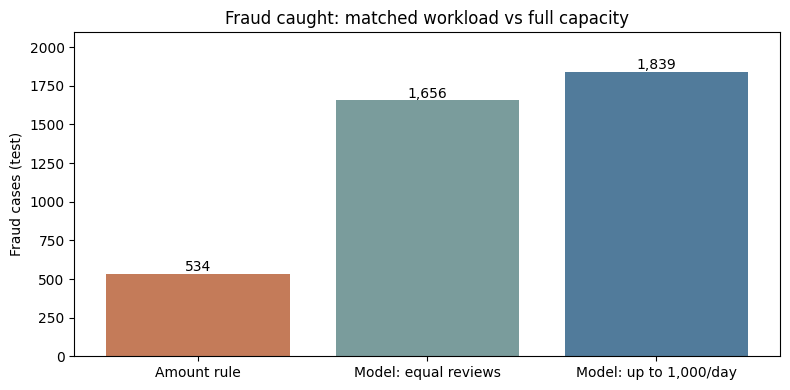

Equal-workload: 5,231 model reviews vs 5,231 rule reviews
Fraud caught: model 1,656, rule 534


In [16]:
# Per-day review budgets equal to the capped rule's actual selected volume.
rule_budget = rule_sel.groupby("day").size().to_dict()
ranked = pd.DataFrame({"day":test_days, "score":test_scores, "fraud":y_test, "row":np.arange(len(y_test))})
ranked.sort_values(["day", "score", "row"], ascending=[True,False,True], inplace=True, kind="mergesort")
ranked["rank"] = ranked.groupby("day", sort=False).cumcount()
ranked["budget"] = ranked.day.map(rule_budget).fillna(0).astype(int)
equal_selected = ranked[ranked["rank"] < ranked["budget"]]
equal_model_caught = int(equal_selected.fraud.sum())
equal_rule_caught = int(rule_sel.isFraud.sum())
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(["Amount rule", "Model: equal reviews", "Model: up to 1,000/day"],
       [equal_rule_caught, equal_model_caught, int(model_sel.y.sum())],
       color=["#c47b59", "#7a9c9c", "#517b9b"])
ax.set(title="Fraud caught: matched workload vs full capacity", ylabel="Fraud cases (test)")
for i, value in enumerate([equal_rule_caught, equal_model_caught, int(model_sel.y.sum())]):
    ax.text(i, value+max(5, int(model_sel.y.sum())*.01), f"{value:,}", ha="center")
ax.set_ylim(0, max(1, int(model_sel.y.sum()))*1.14)
plt.tight_layout(); plt.show()
print(f"Equal-workload: {len(equal_selected):,} model reviews vs {len(rule_sel):,} rule reviews")
print(f"Fraud caught: model {equal_model_caught:,}, rule {equal_rule_caught:,}")

### Review-budget sensitivity (test diagnostic)

A daily budget of 1,000 is a ceiling, not necessarily the economically optimal workload. This curve shows how many labeled frauds would be found at smaller budgets. It is retrospective and exploratory; the choice of a production threshold should be made with review cost and fraud-loss data.

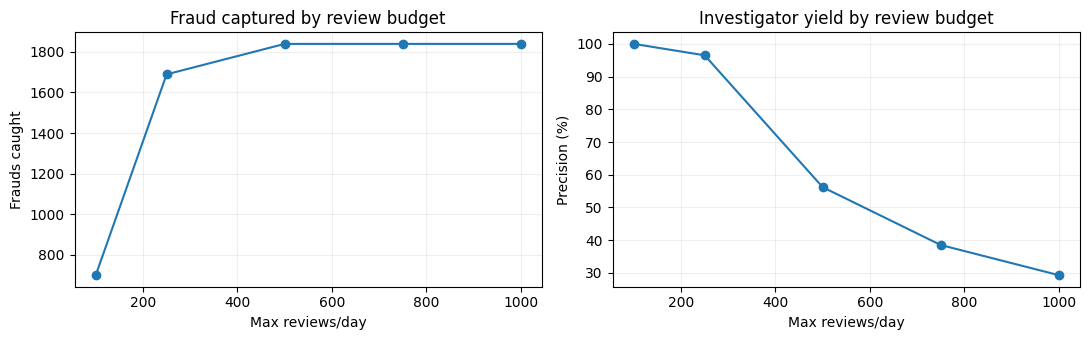

,reviews_per_day_cap,fraud_caught,precision
0,100,700,1.000
1,250,1689,0.965
2,500,1839,0.562
3,750,1839,0.385
4,1000,1839,0.293


In [17]:
budgets = [100, 250, 500, 750, 1000]
curve = []
for budget in budgets:
    picked = ranked.loc[ranked["rank"] < budget]
    caught = int(picked.fraud.sum())
    curve.append({"reviews_per_day_cap": budget, "fraud_caught": caught,
                  "precision": caught / len(picked)})
budget_curve = pd.DataFrame(curve)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(budget_curve.reviews_per_day_cap, budget_curve.fraud_caught, marker="o")
axes[0].set(title="Fraud captured by review budget", xlabel="Max reviews/day", ylabel="Frauds caught")
axes[1].plot(budget_curve.reviews_per_day_cap, budget_curve.precision * 100, marker="o")
axes[1].set(title="Investigator yield by review budget", xlabel="Max reviews/day", ylabel="Precision (%)")
for ax in axes: ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()
display(budget_curve.round(3))

## 6. Model validation and reliability diagnostics

The following checks are **diagnostic**, not a second opportunity to choose a model from the test results. Balance ablation, importance and rolling-window checks use validation or earlier periods; missed-case analysis uses test labels and is explicitly exploratory. These tests are especially important because balance reconciliation showed unusual patterns in this synthetic dataset.

### 6.1 Feature ablation: origin vs destination balances

I refit the same shallow boosting specification on different input groups to isolate how much the result depends on balances. These ablation models do not replace the selected model. They use the full training period.

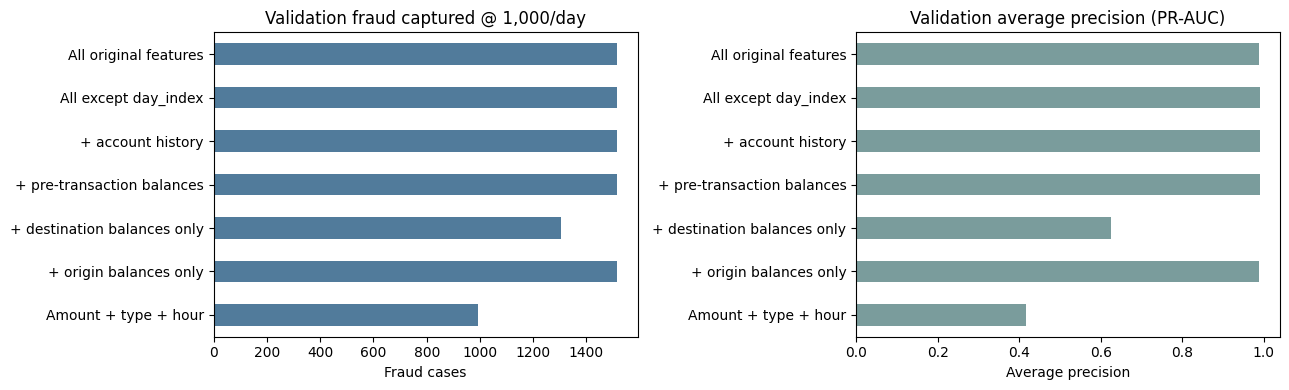

Ablation numeric values (for audit):
                             fraud_caught  recall  pr_auc
feature_set                                              
Amount + type + hour                  993  0.6550  0.4176
+ origin balances only               1516  1.0000  0.9879
+ destination balances only          1306  0.8615  0.6257
+ pre-transaction balances           1516  1.0000  0.9898
+ account history                    1516  1.0000  0.9899
All except day_index                 1516  1.0000  0.9899
All original features                1516  1.0000  0.9884


In [18]:
# Ablation models are diagnostics; they do not replace the validation-selected final model.
base_cols = ["amount_log", "hour_of_day"] + [c for c in FEATURES if c.startswith("type_")]
balance_cols = ["oldbalance_org_log", "oldbalance_dest_log", "amount_to_orig_balance",
                "amount_to_dest_balance", "orig_balance_zero", "dest_balance_zero"]
history_cols = ["orig_prior_count", "dest_prior_count", "orig_prior_amount", "dest_prior_amount"]
feature_groups = {
    "Amount + type + hour": base_cols,
    "+ origin balances only": base_cols + ["oldbalance_org_log", "amount_to_orig_balance", "orig_balance_zero"],
    "+ destination balances only": base_cols + ["oldbalance_dest_log", "amount_to_dest_balance", "dest_balance_zero"],
    "+ pre-transaction balances": base_cols + balance_cols,
    "+ account history": base_cols + balance_cols + history_cols,
    "All except day_index": [c for c in FEATURES if c != "day_index"],
    "All original features": FEATURES,
}
ablation_rows = []
for group_name, cols in feature_groups.items():
    clf = HistGradientBoostingClassifier(max_iter=120, max_leaf_nodes=15, learning_rate=.08,
                                         l2_regularization=2., random_state=RANDOM_SEED)
    clf.fit(features.iloc[train_idx][cols], y_train)
    scores = clf.predict_proba(X_valid[cols])[:, 1]
    metrics = capacity_metrics(y_valid, scores, valid_days, REVIEW_CAP)
    ablation_rows.append({"feature_set":group_name, "fraud_caught":metrics["fraud_caught_total"],
                          "recall":metrics["recall_at_cap"],
                          "pr_auc":average_precision_score(y_valid, scores)})
ablation = pd.DataFrame(ablation_rows).set_index("feature_set")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ablation.fraud_caught.plot.barh(ax=axes[0], color="#517b9b")
axes[0].set(title="Validation fraud captured @ 1,000/day", xlabel="Fraud cases", ylabel="")
ablation.pr_auc.plot.barh(ax=axes[1], color="#7a9c9c")
axes[1].set(title="Validation average precision (PR-AUC)", xlabel="Average precision", ylabel="")
plt.tight_layout(); plt.show()
print("Ablation numeric values (for audit):")
print(ablation.round(4).to_string())


### 6.2 Permutation feature importance (validation diagnostic)

I shuffle one input at a time and measure the drop in average precision. The sample below deliberately includes all validation fraud cases and a subset of legitimate transactions, so its **absolute AP values are not representative of the population**. Correlated balance variables can share predictive signal; grouped ablation is the more reliable way to assess the whole balance feature family.

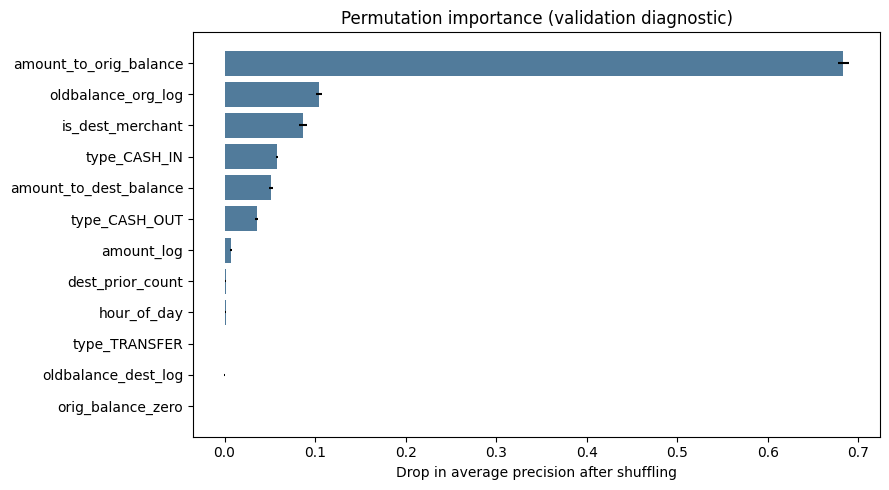

,feature,ap_drop,std
3,amount_to_orig_balance,0.6835,0.0061
1,oldbalance_org_log,0.1045,0.0036
9,is_dest_merchant,0.0871,0.0045
10,type_CASH_IN,0.0580,0.0013
4,amount_to_dest_balance,0.0510,0.0022
11,type_CASH_OUT,0.0354,0.0014
0,amount_log,0.0068,0.0011
17,dest_prior_count,0.0013,0.0003
7,hour_of_day,0.0012,0.0002
14,type_TRANSFER,0.0003,0.0001


In [19]:
from sklearn.inspection import permutation_importance

# A manageable validation sample; include every fraud case for visibility.
# This is a stratified diagnostic sample, so the AP values are not population AP.
val_rng = np.random.default_rng(RANDOM_SEED)
fraud_idx = np.flatnonzero(y_valid == 1)
normal_idx = np.flatnonzero(y_valid == 0)
normal_sample = val_rng.choice(normal_idx, min(18000, len(normal_idx)), replace=False)
importance_idx = np.sort(np.r_[fraud_idx, normal_sample])

importance = permutation_importance(
    best_model, X_valid.iloc[importance_idx], y_valid[importance_idx],
    scoring="average_precision", n_repeats=3,
    random_state=RANDOM_SEED, n_jobs=1
)
importance_df = pd.DataFrame({
    "feature": FEATURES,
    "ap_drop": importance.importances_mean,
    "std": importance.importances_std
}).sort_values("ap_drop", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
top = importance_df.head(12).iloc[::-1]
ax.barh(top.feature, top.ap_drop, xerr=top["std"], color="#517b9b")
ax.set(title="Permutation importance (validation diagnostic)",
       xlabel="Drop in average precision after shuffling")
plt.tight_layout()
plt.show()
display(importance_df.head(12).round(4))

### 6.3 Missed fraud and false positives (exploratory test diagnostics)

I inspect the cases outside the daily top-1,000 and the non-fraud transactions that enter the queue. These observations help identify failure modes but cannot be used to reselect a model on this already-examined test window.

Missed frauds: 1 | Reviewed non-frauds: 4,433


,day,type,amount,oldbalanceOrg,oldbalanceDest,score,daily_rank
80290,26,TRANSFER,399045.08,10399045.08,0.0,0.000004,2544


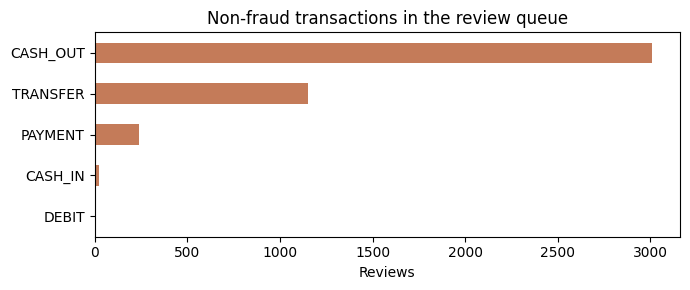

In [20]:
# `ranked` was created in the matched-workload section.
missed = ranked.loc[(ranked.fraud == 1) & (ranked["rank"] >= REVIEW_CAP)].copy()
false_positive = ranked.loc[(ranked.fraud == 0) & (ranked["rank"] < REVIEW_CAP)].copy()

test_raw = df.loc[test_mask].reset_index(drop=True)
inspect_cols = ["day", "type", "amount", "oldbalanceOrg", "oldbalanceDest"]
missed_detail = test_raw.loc[missed.row.to_numpy(), inspect_cols].copy()
missed_detail["score"] = missed.score.to_numpy()
missed_detail["daily_rank"] = missed["rank"].to_numpy() + 1

print(f"Missed frauds: {len(missed):,} | Reviewed non-frauds: {len(false_positive):,}")
display(missed_detail.sort_values(["day", "daily_rank"]))

# How are the model's false positives distributed across transaction types?
fp_types = test_raw.loc[false_positive.row.to_numpy(), "type"].value_counts()
fig, ax = plt.subplots(figsize=(7, 3))
fp_types.sort_values().plot.barh(ax=ax, color="#c47b59")
ax.set(title="Non-fraud transactions in the review queue", xlabel="Reviews", ylabel="")
plt.tight_layout()
plt.show()

### 6.4 New vs returning accounts

A chronological split allows the same account to appear in training and later periods. That is realistic when only past activity is used; the raw account identifiers are not predictors. I check whether the selected review queue still captures fraud for accounts unseen in training.

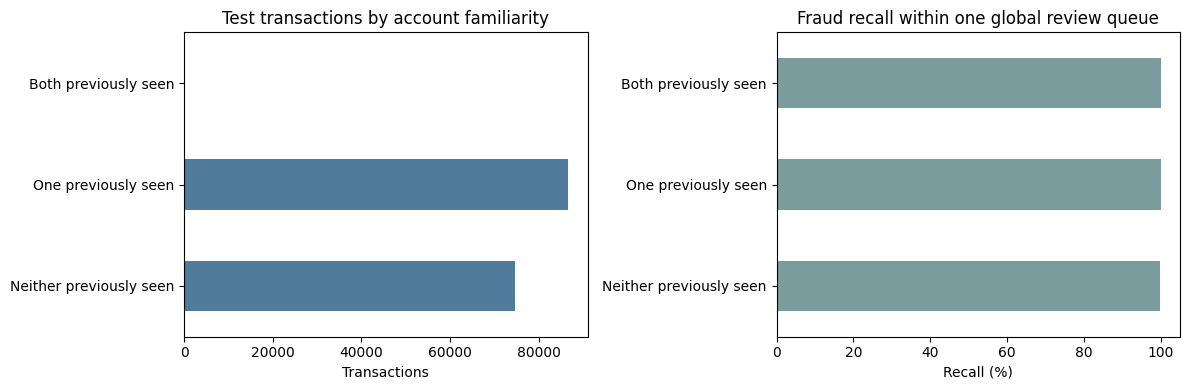

                         transactions  frauds  reviews  caught  fraud_rate  recall_in_global_queue
segment                                                                                           
Neither previously seen         74542    1191     3101    1190      0.0160                  0.9992
One previously seen             86660     646     3164     646      0.0075                  1.0000
Both previously seen              224       3        7       3      0.0134                  1.0000
Note: empty/small segments cannot support a reliable generalization claim.


In [21]:
# Train-seen account flags; do not include raw account IDs in the model.
train_origin = pd.Index(df.loc[train_mask, "nameOrig"].dropna().unique())
train_destination = pd.Index(df.loc[train_mask, "nameDest"].dropna().unique())
test_account = df.loc[test_mask, ["nameOrig", "nameDest"]].copy().reset_index(drop=True)
origin_seen = test_account["nameOrig"].isin(train_origin).to_numpy()
dest_seen = test_account["nameDest"].isin(train_destination).to_numpy()
segment = np.select([origin_seen & dest_seen, origin_seen | dest_seen],
                    ["Both previously seen", "One previously seen"],
                    default="Neither previously seen")
# model_sel.row is the positional row index within the complete test period.
reviewed = np.zeros(len(y_test), dtype=bool)
reviewed[model_sel["row"].to_numpy(dtype=int)] = True
customer_eval = pd.DataFrame({"segment": segment, "fraud": y_test.astype(int),
                              "reviewed": reviewed, "caught": reviewed & (y_test == 1)})
customer_summary = customer_eval.groupby("segment", sort=False).agg(
    transactions=("fraud", "size"), frauds=("fraud", "sum"),
    reviews=("reviewed", "sum"), caught=("caught", "sum"))
customer_summary["fraud_rate"] = customer_summary.frauds / customer_summary.transactions
customer_summary["recall_in_global_queue"] = customer_summary.caught / customer_summary.frauds.replace(0, np.nan)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
customer_summary.transactions.plot.barh(ax=axes[0], color="#517b9b")
axes[0].set(title="Test transactions by account familiarity", xlabel="Transactions", ylabel="")
(customer_summary.recall_in_global_queue * 100).plot.barh(ax=axes[1], color="#7a9c9c")
axes[1].set(title="Fraud recall within one global review queue", xlabel="Recall (%)", ylabel="")
axes[1].set_xlim(0, 105)
plt.tight_layout(); plt.show()
print(customer_summary.round(4).to_string())
print("Note: empty/small segments cannot support a reliable generalization claim.")


### 6.5 Forward-time stability

Two expanding-window checks evaluate earlier windows, before the final test period. These are short-window checks within the same synthetic data, not evidence of long-term production stability. The training sample cap in these **diagnostic rolling fits only** keeps repeated refits manageable; it does not affect the primary model.

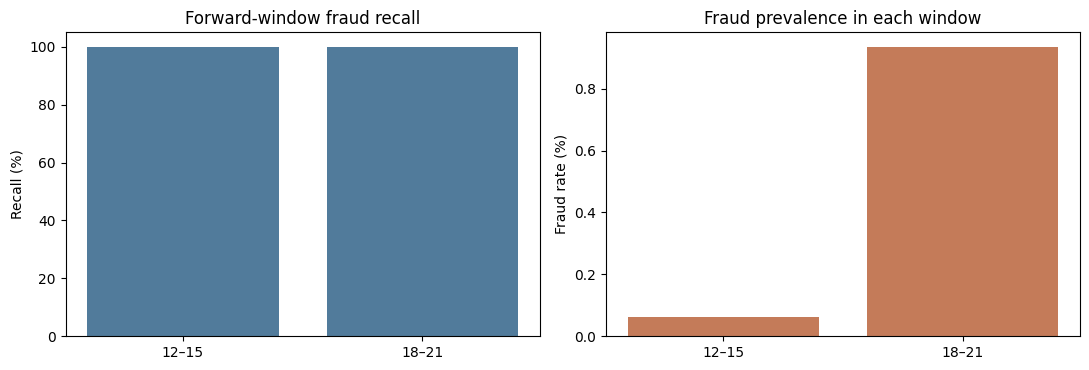

train_days eval_days  eval_transactions  eval_fraud_rate  recall_at_cap  precision_at_cap  reviews_per_day
      0–11     12–15            1603335           0.0006            1.0            0.2475           1000.0
      0–17     18–21             109057           0.0094            1.0            0.2550           1000.0


In [22]:
# Optional: two forward-time checks, using only days before the final test window.
RUN_ROLLING_CHECK = True
ROLLING_TRAIN_SAMPLE = 350_000
rolling_rows = []
if RUN_ROLLING_CHECK:
    # Earlier cutoffs; each four-day assessment must end before the test period.
    for cutoff in [12, 18]:
        eval_end = min(cutoff + 4, int(valid_end))
        fit_idx = np.flatnonzero((df.day < cutoff).to_numpy())
        eval_idx = np.flatnonzero(((df.day >= cutoff) & (df.day < eval_end)).to_numpy())
        if len(fit_idx) == 0 or len(eval_idx) == 0 or len(np.unique(y[fit_idx])) < 2:
            continue
        if len(fit_idx) > ROLLING_TRAIN_SAMPLE:
            fold_rng = np.random.default_rng(RANDOM_SEED + cutoff)
            fit_idx = np.sort(fold_rng.choice(fit_idx, ROLLING_TRAIN_SAMPLE, replace=False))
        fold_model = HistGradientBoostingClassifier(
            max_iter=120, max_leaf_nodes=15, learning_rate=.08,
            l2_regularization=2., random_state=RANDOM_SEED)
        fold_model.fit(features.iloc[fit_idx], y[fit_idx])
        fold_score = fold_model.predict_proba(features.iloc[eval_idx])[:, 1]
        fold_metrics = capacity_metrics(y[eval_idx], fold_score,
                                        df.day.iloc[eval_idx].to_numpy(), REVIEW_CAP)
        rolling_rows.append({"train_days": f"0–{cutoff-1}",
                             "eval_days": f"{cutoff}–{eval_end-1}",
                             "eval_transactions": len(eval_idx),
                             "eval_fraud_rate": y[eval_idx].mean(),
                             "recall_at_cap": fold_metrics["recall_at_cap"],
                             "precision_at_cap": fold_metrics["precision_at_cap"],
                             "reviews_per_day": fold_metrics["reviews_per_day"]})
rolling_results = pd.DataFrame(rolling_rows)
if len(rolling_results):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    x = rolling_results.eval_days
    axes[0].bar(x, rolling_results.recall_at_cap * 100, color="#517b9b")
    axes[0].set(title="Forward-window fraud recall", ylabel="Recall (%)", ylim=(0, 105))
    axes[1].bar(x, rolling_results.eval_fraud_rate * 100, color="#c47b59")
    axes[1].set(title="Fraud prevalence in each window", ylabel="Fraud rate (%)")
    plt.tight_layout(); plt.show()
    print(rolling_results.round(4).to_string(index=False))
else:
    print("Rolling checks disabled or insufficient fraud observations.")


### 6.6 Hourly review allocation

The retrospective daily top-K policy uses all transactions from a day, so it cannot be implemented as-is for immediate decisions. A fixed hourly allocation tests sensitivity to review timing, but is **still a within-hour batch proxy** and does not represent transaction-by-transaction scoring and staffing.

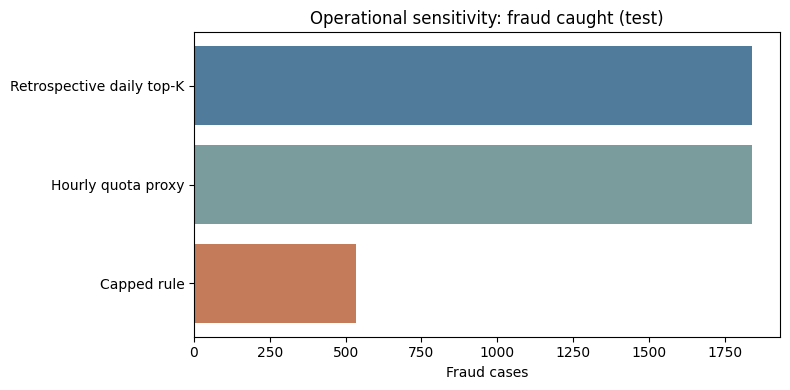

Hourly quota: 3,876 reviews; 1,840 fraud caught
Daily top-K: 6,272 reviews; 1,839 fraud caught
Caveat: hourly selection is still a batch proxy, not per-transaction real-time serving.


In [23]:
# Score each transaction in its own hour, with no cross-hour lookahead.
# 16 hours get 42 slots, 8 hours get 41 slots => exactly 1,000/day.
test_step = df.loc[test_mask, "step"].to_numpy()
hour_bucket = ((test_step.astype(int)-1) % 24)
hourly_budget = np.where(hour_bucket < 16, 42, 41)
hourly = pd.DataFrame({"day":test_days, "step":test_step, "score":test_scores,
                       "fraud":y_test, "hour_cap":hourly_budget, "row":np.arange(len(y_test))})
hourly.sort_values(["step", "score", "row"], ascending=[True,False,True], inplace=True, kind="mergesort")
hourly["hour_rank"] = hourly.groupby("step", sort=False).cumcount()
hour_selected = hourly.loc[hourly.hour_rank < hourly.hour_cap]
fig, ax = plt.subplots(figsize=(8, 4))
values = [int(rule_sel.isFraud.sum()), int(hour_selected.fraud.sum()), int(model_sel.y.sum())]
labels = ["Capped rule", "Hourly quota proxy", "Retrospective daily top-K"]
ax.barh(labels, values, color=["#c47b59", "#7a9c9c", "#517b9b"])
ax.set(title="Operational sensitivity: fraud caught (test)", xlabel="Fraud cases")
plt.tight_layout(); plt.show()
print(f"Hourly quota: {len(hour_selected):,} reviews; {hour_selected.fraud.sum():,} fraud caught")
print(f"Daily top-K: {len(model_sel):,} reviews; {model_sel.y.sum():,} fraud caught")
print("Caveat: hourly selection is still a batch proxy, not per-transaction real-time serving.")


## 7. Operational trade-offs and recommendation

The first chart shows the detection/workload trade-off under different selection policies. The second shows daily results, including the atypical final day. Comparisons across different review counts should not be interpreted as pure model-quality comparisons; the matched-workload result is the fair efficiency comparison.

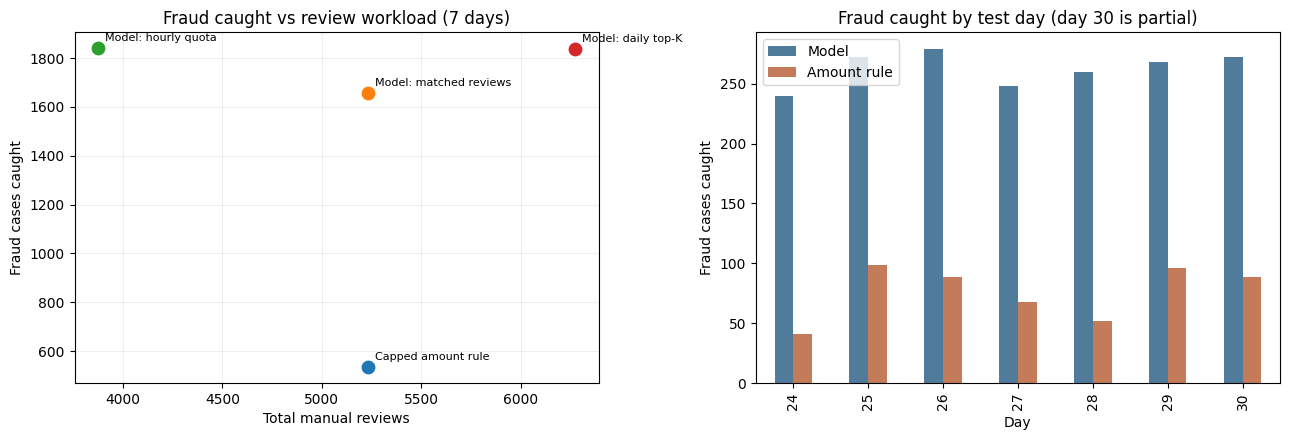

,policy,reviews,fraud_caught
0,Capped amount rule,5231,534
1,Model: matched reviews,5231,1656
2,Model: hourly quota,3876,1840
3,Model: daily top-K,6272,1839


Full 24-hour days:
Model: 1,567 frauds / 6,000 reviews
Rule:  445 frauds / 5,142 reviews


In [24]:
# Consolidate the operational trade-off in one chart.
policy_summary = pd.DataFrame({
    "policy": ["Capped amount rule", "Model: matched reviews",
               "Model: hourly quota", "Model: daily top-K"],
    "reviews": [len(rule_sel), len(equal_selected), len(hour_selected), len(model_sel)],
    "fraud_caught": [int(rule_sel.isFraud.sum()), int(equal_selected.fraud.sum()),
                     int(hour_selected.fraud.sum()), int(model_sel.y.sum())]
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for _, item in policy_summary.iterrows():
    axes[0].scatter(item.reviews, item.fraud_caught, s=80)
    axes[0].annotate(item.policy, (item.reviews, item.fraud_caught),
                     xytext=(5, 5), textcoords="offset points", fontsize=8)
axes[0].set(title="Fraud caught vs review workload (7 days)",
            xlabel="Total manual reviews", ylabel="Fraud cases caught")
axes[0].grid(alpha=0.2)

daily[["model_caught", "rule_caught"]].plot.bar(
    ax=axes[1], color=["#517b9b", "#c47b59"])
axes[1].set(title="Fraud caught by test day (day 30 is partial)",
            xlabel="Day", ylabel="Fraud cases caught")
axes[1].legend(["Model", "Amount rule"])
plt.tight_layout(); plt.show()
display(policy_summary)

print("Full 24-hour days:")
print(f"Model: {int(full.model_caught.sum()):,} frauds / {int(full.model_reviews.sum()):,} reviews")
print(f"Rule:  {int(full.rule_caught.sum()):,} frauds / {int(full.rule_reviews.sum()):,} reviews")

### Decision and limitations

**Recommendation: controlled shadow pilot, not immediate replacement.** On the held-out chronological test window, risk-based ranking caught more labeled fraud than the capped amount rule at the same review workload (1,656 vs 534 at 5,231 reviews). This suggests an opportunity to improve investigator prioritization, not a validated production uplift.

**Balance dependence is the main model risk.** In validation ablation, origin balance features accounted for most of the gain over amount, type, and time alone. Permutation importance identified `amount_to_orig_balance` as the strongest individual signal. These results are consistent with the unusual fraud/non-fraud balance patterns identified during data validation, and may reflect synthetic data-generation shortcuts. They do not by themselves establish future-information leakage: only pre-transaction balance fields were used for modeling. Their availability, timing, semantics and stability in real operations still need verification.

**Operational and evaluation limitations.** The dataset is synthetic, fraud prevalence and transaction volume shift sharply over time, and the final test day contains only 272 transactions, all labeled fraud. Daily top-K assumes a full day of scores is available before review; the hourly quota experiment still ranks within completed hourly batches, so neither is a live arrival-time policy. The test window has been inspected during development, and additional test diagnostics are exploratory rather than independent confirmation.

**Next step:** verify balance-feature semantics and decision-time availability, run the model in shadow mode alongside the rule, test an arrival-time queue within staffing limits, and monitor matured fraud labels, precision, recall, false positives and investigator effort. Consider a limited rollout only if improvements persist on new real-world data. No production savings or prevented-loss estimate is supported without review costs, fraud amounts at risk and intervention effectiveness.

In [25]:
# Generate a numerical summary from this run; use it to update the retained
# Executive Summary before sharing the notebook.
model_caught = int(model_sel.y.sum())
rule_caught = int(rule_sel.isFraud.sum())
matched_caught = int(equal_selected.fraud.sum())
frauds = int(y_test.sum())
print(f"Selected model: {best_name}")
print(f"Test frauds: {frauds:,}")
print(f"Capped rule: {rule_caught:,} frauds / {len(rule_sel):,} reviews")
print(f"Model, matched workload: {matched_caught:,} frauds / {len(equal_selected):,} reviews")
print(f"Model, daily cap: {model_caught:,} frauds / {len(model_sel):,} reviews")
print(f"Model recall at cap: {model_caught / frauds:.2%}")
print("These are retrospective synthetic-data results, not production forecasts.")

Selected model: Boosting (compact, 180)
Test frauds: 1,840
Capped rule: 534 frauds / 5,231 reviews
Model, matched workload: 1,656 frauds / 5,231 reviews
Model, daily cap: 1,839 frauds / 6,272 reviews
Model recall at cap: 99.95%
These are retrospective synthetic-data results, not production forecasts.
